# Deep Agents

## Definition
Deep Agents are AI agents designed to handle complex, multi-step tasks through planning, task decomposition, subagent delegation, and file-system-based context management. Deep Agents is a standalone library built on LangGraph and inspired by applications like Claude Code, Deep Research, and Manus. It provides built-in capabilities for planning, managing context, and coordinating specialized subagents.

---

## How Deep Agents Work

1. **User Input:** Receives a complex task from the user.
2. **Planning:** Breaks the task into smaller steps and creates a plan.
3. **Task Delegation:** Assigns suitable subtasks to specialized subagents when needed.
4. **Execution:** Uses tools, file systems, and subagents to complete the planned tasks.
5. **Context Management:** Stores and retrieves relevant information using file-system tools to manage large amounts of context.
6. **Result Integration:** Combines the results from different subtasks into a coherent output.
7. **Final Response:** Returns the completed result to the user.

**Workflow:** User Input → Planning → Task Decomposition → Subagent Delegation & Tool Execution → Result Integration → Final Output

---

## When to Use Deep Agents
Use deep agents when you need agents that can:

- **Complex Tasks:** When a task requires multiple steps, planning, and execution.
- **Large Context:** When an agent needs to manage large amounts of information using file-system tools.
- **Task Delegation:** When work can be divided among specialized subagents.
- **Persistent Memory:** When an agent needs to retain information across conversations and threads.

---

## Benefits of Deep Agents

- **Planning & Decomposition:** Breaks complex tasks into smaller, manageable subtasks.
- **Subagent Support:** Delegates tasks to specialized agents with isolated contexts.
- **File-System Integration:** Stores, reads, and manages files to organize information and handle large contexts.
- **Context Management:** Helps prevent the main agent's context from becoming overloaded.
- **Long-Running Workflows:** Supports complex tasks that require multiple stages of execution.
- **Memory & Continuity:** Can preserve relevant information across interactions when persistence is configured.

---

## Deep Agents — Hands-on Implementation

### Environment Setup

In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

### Create a Web Search Tool
Use Tavily to search the internet and retrieve relevant information.

In [ ]:
from typing import Literal
from tavily import TavilyClient

tavily_client=TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

def web_search(query:str, 
               max_results:int=5, 
               topic:Literal["general", "sports", "news", "finance"]="general", 
               include_raw_content:bool=False):
    """"Run a Web Search"""
    return tavily_client.search(query=query, 
                                max_results=max_results, 
                                include_raw_content=include_raw_content,
                                topic=topic)

### Initialize the Language Model
Initialize the Groq-hosted GPT-OSS 120B model using LangChain.

In [14]:
from langchain.chat_models import init_chat_model

model=init_chat_model("groq:openai/gpt-oss-120b")
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.10', 'langchain': '1.4.5'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001A3E5315BD0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001A3E53165D0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

### Build a Basic Agent
Create a basic LangChain agent with access to the web search tool.

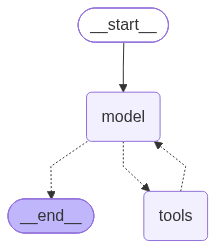

In [ ]:
from langchain.agents import create_agent

simple_agent=create_agent(
    model=model,
    tools=[web_search]
)

simple_agent

### Build a Deep Agent
Create a Deep Agent using the same model and search tool, with a system prompt that defines its role as a researcher.

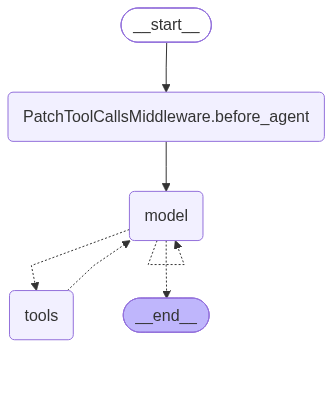

In [ ]:
from deepagents import create_deep_agent

deep_agent=create_deep_agent(
    model=model,
    tools=[web_search],
    system_prompt="Act as a researcher"
)

deep_agent


### Execute the Deep Agent
Provide a research question and invoke the agent.

In [17]:
result=deep_agent.invoke({"messages": [{"role":"user", "content": "What is Deep Agents?"}]})
result

{'messages': [HumanMessage(content='What is Deep Agents?', additional_kwargs={}, response_metadata={}, id='166570e1-0117-4949-8ce1-a55b9fe2defb'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to answer the user question: "What is Deep Agents?" As a researcher, we should provide a comprehensive explanation. Possibly we need to browse the filesystem for any relevant docs, but likely the user just asks general knowledge. We can answer from our knowledge. Deep Agents could refer to a concept in AI: "Deep Agents" might be a term for agents using deep learning for decision-making, like deep reinforcement learning agents. Could also be a specific library or project named "DeepAgents". Let\'s recall: There\'s a "DeepMind Agents"? There\'s "Deep Agent" in some contexts. Might be a paper: "Deep Agents: Learning to Learn in a Multi-Agent Environment"? Or "Deep Agents: A System for Multi-Agent Reinforcement Learning"? Could also refer to "Deep Agents" from OpenAI? Not s

### Extract the Final Response
Retrieve the content of the last message returned by the agent.

In [18]:
result["messages"][-1].content

'**Deep Agents – A Research‑oriented Overview**\n\n---\n\n### 1. Core Definition  \n\n**Deep Agents** are autonomous decision‑making systems that combine **deep learning** (neural networks with many layers) with the **agent‑oriented paradigm** of artificial intelligence. In practice, a Deep Agent perceives its environment through raw, high‑dimensional sensory data (e.g., images, audio, text), processes that data with deep neural models to infer latent state or directly predict actions, and then executes those actions in a (usually) sequential, goal‑directed loop.\n\n| Component | Traditional AI Agent | Deep Agent |\n|-----------|----------------------|------------|\n| **Perception** | Hand‑crafted features, symbolic representations | End‑to‑end learned feature extraction (CNNs, RNNs, Transformers, etc.) |\n| **Decision Policy** | Rule‑based, planning, reinforcement‑learning with tabular/value‑function approximations | Policy/value networks, actor‑critic, hierarchical RL, model‑based de

In [19]:
result["files"]

{}

## What Happened Behind the Scenes?

When the Deep Agent received the research task, it automatically performed the following steps:

- **Planning & Task Decomposition:** Used the built-in `write_todos` tool to break the research task into manageable steps.
- **Web Research:** Called the `web_search` tool to gather relevant information from the internet.
- **Context Management:** Used file-system tools such as `write_file` and `read_file` to store and retrieve large amounts of information.
- **Subagent Delegation:** Spawned specialized subagents when needed to handle complex subtasks independently.
- **Report Synthesis:** Combined the research findings into a coherent and well-structured final response.